# Bonus B3: How to build a typed agent with Pydantic AI

**Notebook 1 of 2: meet Pydantic AI on movie night**

## Goal

Ask an agent to pick a film for movie night and get the pick back as a Python object that our code can read, where a
plain model call gives a paragraph. Then make our code check the pick: the film has to suit the youngest person
on the sofa, and a pick that does not is sent back to the model with the reason. The pick that gets sent back has every
field of the right type. A typed answer and a right answer are two different checks, and this notebook builds both.
Nothing here touches the music shop yet. This notebook is the playground; notebook 2 takes the same library to the
Chinook support desk.

## What you will learn

- How to describe an answer as a Pydantic model and get it back from an agent with `output_type`.
- How to read, from a run's messages, how the typed answer travelled from the model to our code.
- How to pass a fact our code has to a run with `deps`, and read it through `RunContext` in a validator and in a tool.
- How to reject a well-typed answer with an output validator and `ModelRetry`, and find the correction the model was
  sent.
- How to test the validator with `TestModel`, with no API call.
- How to chat with the agent in a terminal and in a browser.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Pydantic AI names a model as `provider:model`, so we put `openai:` in front of the name from `models.env`.

`SETTINGS` goes to every agent in this notebook. It carries two things: the reasoning effort from `models.env`, and
a limit of 60 seconds on each model request, so a request that gets stuck fails quickly.

In [2]:
MODEL_NAME = "openai:" + MODEL
SETTINGS = {"openai_reasoning_effort": EFFORT, "timeout": 60}

---

## Part A: Ask for a film and read what comes back

It is movie night, and somebody has to choose. We ask a model:

> Pick a scary film for movie night tonight.

### The smallest agent

In Pydantic AI an `Agent` is the object we send questions to. The smallest one needs only a model name.
`agent.run(question)` sends the question, and the reply is in `result.output`.

**Why `await`?** `agent.run` is an `async` function: calling it prepares the work, and `await` runs it and waits for
the result. A notebook lets us write `await` directly in a cell.

In [3]:
from pydantic_ai import Agent

QUESTION = "Pick a scary film for movie night tonight."

agent = Agent(MODEL_NAME, model_settings=SETTINGS)
result = await agent.run(QUESTION)

print(type(result.output).__name__)
print(result.output)

str
**Watch *The Descent* (2005).** It’s a tense, claustrophobic cave-survival horror film with genuinely frightening moments—great for a movie night if you’re in the mood to be on edge.


`result.output` is a `str`: a sentence or two naming a film, in the model's own words. Your film and your wording may
differ from ours.

A person can read that. A program cannot do much with it. Suppose the next step of our app is to check the film's age
rating, or to work out when the film ends. The rating and the running time may be somewhere in the sentence, in
whatever words the model chose this time, or they may not be there at all. We would have to search the text for them,
and the search finds nothing when the model left them out.

**Checkpoint A.** The reply is a `str`. It names a film, and nothing in it is a field we can read by name.

---

## Part B: Describe the pick as a Pydantic model and get it back as an object

What our code needs from a pick is three facts, each with a name and a type. We write that down first, with no model
involved, and then ask the agent for it.

### The shape of a pick

[Pydantic](https://docs.pydantic.dev/latest/concepts/models/) is the library Pydantic AI is built on. A Pydantic model
is a class that lists fields and their types. Pydantic calls such a class a *model*; in this lab, *the model* on its
own always means the language model.

- `title: str` is the film's name, as text.
- `age_rating` must be one of four values. `Literal[...]` lists them. They are four of the ratings films carry in the
  United States: `G` (all ages), `PG` (parents may want to check first), `PG-13` (parents strongly cautioned for
  children under 13), `R` (under 17 only with an adult).
- `minutes: int` is the running time, as a whole number.

We build one pick by hand to see what the object gives us.

In [4]:
from typing import Literal
from pydantic import BaseModel


class MoviePick(BaseModel):
    title: str
    age_rating: Literal["G", "PG", "PG-13", "R"]
    minutes: int


pick = MoviePick(title="Paddington 2", age_rating="PG", minutes=103)

print(pick)
print("rating:", pick.age_rating)
print("ends after:", pick.minutes // 60, "h", pick.minutes % 60, "min")

title='Paddington 2' age_rating='PG' minutes=103
rating: PG
ends after: 1 h 43 min


Each fact has a name: `pick.age_rating` is `'PG'`. And `pick.minutes` is a number, so we can calculate with it:
`103 // 60` is 1 whole hour and `103 % 60` is the 43 minutes left over.

### What Pydantic refuses

A Pydantic model also checks what we put in it. We hand it a rating that is not one of the four and a running time
that is not a number.

In [5]:
from pydantic import ValidationError

try:
    MoviePick(title="Jaws", age_rating="scary", minutes="about two hours")
except ValidationError as error:
    for problem in error.errors():
        print(problem["loc"], "|", problem["msg"])

('age_rating',) | Input should be 'G', 'PG', 'PG-13' or 'R'
('minutes',) | Input should be a valid integer, unable to parse string as an integer


Two problems, one line each. `loc` names the field and `msg` says what is wrong with it: `age_rating` has to be one of
the four ratings, and `minutes` has to be a whole number. The title passed, so it is not listed. No `MoviePick` was
created.

This is what "typed" means for the rest of the lab: every field is present and every value has the declared type.

### Ask the agent for that object

`output_type=MoviePick` tells the agent what a finished answer looks like. The question does not change.

In [6]:
picker = Agent(MODEL_NAME, output_type=MoviePick, model_settings=SETTINGS)
result = await picker.run(QUESTION)

pick = result.output
print(type(pick).__name__)
print(pick)
print("rating:", pick.age_rating)
print("ends after:", pick.minutes // 60, "h", pick.minutes % 60, "min")

MoviePick
title='The Conjuring' age_rating='R' minutes=112
rating: R
ends after: 1 h 52 min


This time `result.output` is a `MoviePick`, not a `str`. The rating and the running time are fields, and the same two
lines we wrote for Paddington 2 work on the model's pick.

### How the object got here

A model writes text. So how did a Python object come out? The run keeps every message that went to the model and came
back, in `result.all_messages()`:

- a `ModelRequest` is what was sent to the model;
- a `ModelResponse` is what the model sent back;
- each message is made of **parts**. We print each part's type and what it carries.

In [7]:
def show_messages(result):
    for message in result.all_messages():
        print(type(message).__name__)
        for part in message.parts:
            name = getattr(part, "tool_name", "")
            content = getattr(part, "args", None) or part.content
            print("   ", type(part).__name__, "|", name, "|", content)


show_messages(result)

ModelRequest
    UserPromptPart |  | Pick a scary film for movie night tonight.
ModelResponse
    ToolCallPart | final_result | {"title":"The Conjuring","age_rating":"R","minutes":112}
ModelRequest
    ToolReturnPart | final_result | Final result processed.


Three messages:

1. **`ModelRequest`, `UserPromptPart`:** our question.
2. **`ModelResponse`, `ToolCallPart`:** the model did not answer with text. It asked for a tool called `final_result`,
   and the arguments are a string of JSON with our three fields.
3. **`ModelRequest`, `ToolReturnPart`:** the library's reply to that call, *Final result processed.*

We never wrote a tool called `final_result`. Pydantic AI made it from `MoviePick`: the tool's parameters are
`MoviePick`'s fields, and the request tells the model it must call a tool. The model fills in the arguments, Pydantic
checks them exactly as it checked our hand-made pick, and the checked object becomes `result.output`. So with an
`output_type` the run ends when the model calls an output tool, not when it replies with plain text. Sending the shape
as a tool is Pydantic AI's default; other libraries send it as the API's own structured-output setting, and Pydantic
AI can do that too (`NativeOutput`, in the Output documentation). If the model's arguments fail Pydantic's check (a
rating of `scary`), the run does not crash: Pydantic AI sends Pydantic's error messages back to the model and asks it
to try again. Part C uses the same retry for a rule of our own. In `show_messages`, `getattr(part, "tool_name", "")`
reads a part's tool name when it has one; a user prompt does not.

### A well-typed pick that is wrong for a 9-year-old

Now look at the pick itself. In our run it was *The Conjuring*, rated `R`.

The question did not say that my little sister is 9 and watches with us. `R` is one of the four allowed values, so
Pydantic accepted it. Every field is present and every type is correct. The pick is still wrong for our sofa.

The model is not at fault. Nobody told it who is watching. Our app has that fact, and the next part passes it in.

**Checkpoint B.** `result.output` is a `MoviePick`. The messages show a `final_result` tool call that carries the
three fields as JSON. The pick is rated `PG-13` or `R` (ours was `R`).

---

## Part C: Pass who is watching with `deps`, and check the pick with an output validator

Two things are missing. Our code has to tell the run who is watching, and something has to check the pick against that
before we accept it.

### Who is watching, as a `Viewer` object

Who is watching is not part of the question. It belongs to our app: think of a family profile that the app reads when
movie night starts. We keep it in a small dataclass. `@dataclass` writes the constructor for us from the field list,
so `Viewer(age=9)` works. We will pass this object to the run as `deps`. `deps` is never sent to the model or checked by Pydantic, so any Python object will do; a
dataclass is the shortest way to name its fields.

In [8]:
from dataclasses import dataclass


@dataclass
class Viewer:
    age: int


tonight = Viewer(age=9)
print(tonight)

Viewer(age=9)


### The house rule, in plain Python

Before any library is involved, we write the rule and try it by hand. `MIN_AGE` gives, for each rating, the youngest
age that may watch it in our house. The numbers are our family's choice. (Only `R` comes with an age the cinema
enforces; the other ages are ours.)

The check is one comparison: is the rating's minimum age above the viewer's age?

In [9]:
MIN_AGE = {"G": 0, "PG": 8, "PG-13": 13, "R": 17}

print("the pick from Part B:", pick.title, "|", pick.age_rating)
print("minimum age for that rating:", MIN_AGE[pick.age_rating])
print("too old for tonight's viewer:", MIN_AGE[pick.age_rating] > tonight.age)

the pick from Part B: The Conjuring | R
minimum age for that rating: 17
too old for tonight's viewer: True


`True`: the rule catches Part B's pick. Now we want the agent to apply this rule to every pick, and to try again when
a pick fails it.

### The same rule as an output validator

Three new names, all from Pydantic AI:

- **`deps_type=Viewer`** tells the agent what kind of object our code will pass to each run. "Deps" is short for
  dependencies: what a run depends on that is not in the question.
- **`@careful.output_validator`** registers the function below it as a check on every answer of the agent `careful`.
  It runs in our Python after Pydantic has checked the types, and before the answer becomes `result.output`.
- **`RunContext`** is the first argument the validator receives. `ctx.deps` is the object we pass to the run, here
  our `Viewer`.

The validator does one of two things. It **returns** the pick, which accepts it. Or it **raises `ModelRetry`** with a
message, which rejects the pick and sends that message to the model, so the model can answer again.

The first line of the validator prints what it was given. That print shows every pick the model proposed,
including the ones we never receive.

In [10]:
from pydantic_ai import ModelRetry, RunContext

careful = Agent(MODEL_NAME, output_type=MoviePick, deps_type=Viewer, model_settings=SETTINGS)


@careful.output_validator
def check_age(ctx: RunContext[Viewer], pick: MoviePick) -> MoviePick:
    print("validator saw:", pick.title, "|", pick.age_rating)

    if MIN_AGE[pick.age_rating] > ctx.deps.age:
        allowed = [rating for rating, age in MIN_AGE.items() if age <= ctx.deps.age]
        raise ModelRetry(
            f"{pick.title} is rated {pick.age_rating}, and the youngest viewer is {ctx.deps.age}. "
            f"Pick a film rated {' or '.join(allowed)}."
        )

    return pick

`allowed` is the list of ratings whose minimum age is not above the viewer's age. For a 9-year-old that is `G` and
`PG`. We put it in the message so the model is told what would pass, not only what failed.

We ask the same question as before. The only change in the call is `deps=tonight`. Before you run it: how many
`validator saw` lines do you expect?

In [11]:
result = await careful.run(QUESTION, deps=tonight)

print()
print("final pick:    ", result.output)
print("model requests:", result.usage.requests)

validator saw: The Thing | R


validator saw: Coraline | PG

final pick:     title='Coraline' age_rating='PG' minutes=100
model requests: 2


Two `validator saw` lines. The first pick was rated above what a 9-year-old may watch, so the validator raised
`ModelRetry`. The second pick is rated `PG`, the validator returned it, and only that one reached `result.output`.
In our run the first pick was *The Thing* and the second *Coraline*: still a scary film, and one a 9-year-old can
watch.

`model requests: 2`: the rejection cost one more request to the model.

### Find the correction the model was sent

We print the messages again with `show_messages`. Look for the part that follows the first `final_result` call.

In [12]:
show_messages(result)

ModelRequest
    UserPromptPart |  | Pick a scary film for movie night tonight.
ModelResponse
    ToolCallPart | final_result | {"title":"The Thing","age_rating":"R","minutes":109}
ModelRequest
    ToolReturnPart | final_result | The Thing is rated R, and the youngest viewer is 9. Pick a film rated G or PG.
ModelResponse
    ToolCallPart | final_result | {"title":"Coraline","age_rating":"PG","minutes":100}
ModelRequest
    ToolReturnPart | final_result | Final result processed.


Five messages this time. The model called `final_result` twice:

- After the first call, the `ToolReturnPart` no longer says *Final result processed.* It carries the text of our
  `ModelRetry`, word for word. To the model, our rejection is the result of the tool it called.
- The model then called `final_result` again with a new pick, and that one was processed.

So each refusal adds two parts to the messages: the model's proposal, as a `final_result` call, and our reason for
refusing it, as that call's result.

**Important:** look at what the validator trusted. It compared the viewer's age with `pick.age_rating`, and the model
wrote that rating from its training data. If the model had written `PG` for an `R` film, this check would have passed
it. Here that is good enough for a film night. Where it is not, the validator reads the fact from a record of our own,
and notebook 2 does that with the shop's database.

**In production:** tell the model the rule as well, so that it gets it right the first time, and keep the validator.
The instruction is a request to the model. The validator is our code, and it runs on every answer.

**Checkpoint C.** `validator saw` prints twice: first a pick rated `PG-13` or `R`, then one rated `G` or `PG`. The run
made 2 model requests. The messages contain two `final_result` calls, and the reply to the first one is the text of
our `ModelRetry`.

---

## Part D: Let the model ask for the rule with a tool that reads `deps`

The validator works, but the model's first pick was wasted: the model had to guess, be refused, and guess again. The
model could do better if it had a way to ask which ratings are allowed before it picks.

A **tool** is a Python function the model may ask us to run. `@careful.tool` adds one to the agent we already have:

- the function's name and its docstring are what the model is shown;
- `ctx` is filled in by Pydantic AI, as in the validator, and the model never sees it. From the model's side
  this tool takes no arguments at all;
- the return value is sent back to the model.

As with the validator, a print at the top tells us when it ran.

In [13]:
@careful.tool
def allowed_ratings(ctx: RunContext[Viewer]) -> list[str]:
    """The age ratings tonight's youngest viewer may watch."""
    print("TOOL CALLED: allowed_ratings")
    return [rating for rating, age in MIN_AGE.items() if age <= ctx.deps.age]

The same question and the same `deps`. We also print which tools the model called, in order, by collecting the
`ToolCallPart`s from the messages.

In [14]:
result = await careful.run(QUESTION, deps=tonight)

print()
print("final pick:    ", result.output)
print("model requests:", result.usage.requests)
print("tools called:  ", [part.tool_name for message in result.all_messages()
                          for part in message.parts if type(part).__name__ == "ToolCallPart"])

TOOL CALLED: allowed_ratings


validator saw: Coraline | PG

final pick:     title='Coraline' age_rating='PG' minutes=100
model requests: 2
tools called:   ['allowed_ratings', 'final_result']


`TOOL CALLED` comes first: the model asked for the allowed ratings before it picked. Then `validator saw` prints once,
with a film rated `PG`, and that pick is accepted. The agent has no instructions at all, so nothing told the model to
call the tool. The request carried the tool's name and description, and the model asked for it.

Still 2 model requests: one that asked for the tool, and one that answered. The count is the same as in Part C, and no
pick was thrown away.

The tool and the validator read the same `deps`, and they do different jobs:

| | Tool | Output validator |
|---|---|---|
| Who decides that it runs | the model, by asking for it | our code, on every answer |
| When it runs | before the answer | after the answer, before we receive it |
| What it is for | giving the model a fact it needs | refusing an answer that breaks a rule |
| If the model ignores it | the model guesses | cannot be ignored |

That last row is why we keep both. The tool helps the model get it right. The validator still runs when it does not.

### A picture of one run, from the question to `result.output`

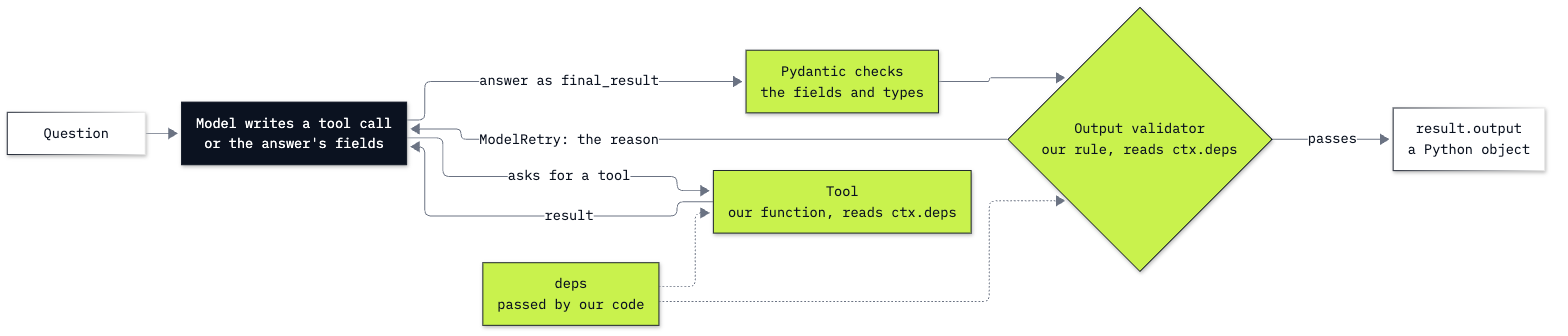

In [15]:
from IPython.display import Image

Image("resources/b3_typed_run.png", width=760)

The dark box is the model: it writes a tool call or the fields of an answer, and nothing else. The lime boxes are our
code and the library running in our Python: the tool, Pydantic's check of the types, and our validator. The dotted
lines are `deps`, which our code passes in and the model never receives. The arrow back from the validator to the
model is `ModelRetry`.

**Checkpoint D.** `TOOL CALLED: allowed_ratings` prints before a single `validator saw` line. The tools called are
`allowed_ratings`, then `final_result`. The final pick is rated `G` or `PG`.

---

## Part E: Test the validator with no API call

So far we have checked the validator by asking a real model and reading what it happened to pick. That costs a
request every time, and it only tests the rule when the model's first pick breaks it. A test should break the rule on
purpose, every time.

Pydantic AI ships a stand-in for the model, `TestModel`. It makes no request to anyone:

- it calls every tool the agent has, once;
- then it answers with `custom_output_args`, the fields we give it, as a `final_result` call.

Everything on our side still runs: the tool, Pydantic's check and the validator.

First a safety switch. With `models.ALLOW_MODEL_REQUESTS = False`, any attempt to reach a real model raises an error.
We try one real run to see the switch work.

In [16]:
from pydantic_ai import models

models.ALLOW_MODEL_REQUESTS = False

try:
    await careful.run(QUESTION, deps=tonight)
except RuntimeError as error:
    print("RuntimeError:", error)

RuntimeError: Model requests are not allowed, since ALLOW_MODEL_REQUESTS is False


The real model is out of reach. Now the test. `always_conjuring` is a `TestModel` that answers *The Conjuring*, rated
`R`, whatever it is asked. `careful.override(model=...)` swaps it in for the lines inside the `with` block.

For a 9-year-old, a correct validator must never let that pick through. Before you run it: what will `careful.run`
do when every answer is refused?

In [17]:
from pydantic_ai.exceptions import UnexpectedModelBehavior
from pydantic_ai.models.test import TestModel

always_conjuring = TestModel(custom_output_args={"title": "The Conjuring", "age_rating": "R", "minutes": 112})

with careful.override(model=always_conjuring):
    try:
        await careful.run(QUESTION, deps=Viewer(age=9))
        print("❌ the R-rated pick got through")
    except UnexpectedModelBehavior as error:
        print("✅ no pick for the 9-year-old:", error)

TOOL CALLED: allowed_ratings
validator saw: The Conjuring | R
validator saw: The Conjuring | R
✅ no pick for the 9-year-old: Exceeded maximum output retries (1)


The tool ran, and the validator saw *The Conjuring* twice. A `TestModel` cannot change its answer, so the second try
was the same film, and the run stopped with `Exceeded maximum output retries (1)`.

Two things to take from that line:

- **The run raised `UnexpectedModelBehavior` and returned nothing.** An agent allows one retry of the answer unless we say otherwise
  (`Agent(..., retries=3)` allows three). When the retries run out, our code gets an exception it can catch. It does
  not get the refused pick.
- **The ✅ line states what the test establishes:** with this validator, an `R` pick cannot reach a 9-year-old. It
  says nothing about what a real model will pick.

A rule also has to let the right cases through. The same film for a 17-year-old:

In [18]:
with careful.override(model=always_conjuring):
    result = await careful.run(QUESTION, deps=Viewer(age=17))

print("✅ the 17-year-old gets:", result.output.title, "|", result.output.age_rating)

models.ALLOW_MODEL_REQUESTS = True

TOOL CALLED: allowed_ratings
validator saw: The Conjuring | R
✅ the 17-year-old gets: The Conjuring | R


One `validator saw` line and the pick is returned: the rule blocks the 9-year-old and lets the 17-year-old through.
The only thing we changed between the two tests was `deps`. This is the gain from passing facts in with `deps`: the
test chooses the viewer, and nothing inside the agent had to change.

The last line switches real requests back on for the rest of the notebook.

**Checkpoint E.** With requests switched off, the real run raises `RuntimeError`. With `always_conjuring` and a
9-year-old, the run ends in `UnexpectedModelBehavior` after two `validator saw` lines. With a 17-year-old it returns
*The Conjuring*.

---

## Part F: Chat with the agent in a terminal and in a browser

A notebook runs one question at a time. Pydantic AI can also put an agent behind a chat, in the terminal or in a web
page, with one line each. Both need the agent in a Python file, so the lab's folder has one: `movie_night.py`. We
print it.

In [19]:
LAB = ROOT / "bonus" / "B3_PydanticAI_Typed_Agent"

print((LAB / "movie_night.py").read_text())

"""Movie night: the agent from notebook 1 in one file, so it can run as a terminal chat or a web chat.

Terminal chat:  python movie_night.py
Web chat:       uvicorn movie_night:app --host 127.0.0.1 --port 7932    (from this folder)
"""
from dataclasses import dataclass
from pathlib import Path
from typing import Literal
import os

from dotenv import dotenv_values
from pydantic import BaseModel
from pydantic_ai import Agent, ModelRetry, RunContext

# The model name comes from models.env and the key from the environment or .env, as in the notebooks
ROOT = next(p for p in Path(__file__).resolve().parents if (p / "models.env").exists())
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")

# The house rule: the youngest age that may watch each rating
MIN_AGE = {"G": 0, "PG": 8, "PG-13": 13, "R

The file is this notebook in one place: the same `MoviePick`, `Viewer`, `MIN_AGE`, tool and validator, without the
prints. Its first lines find `models.env` and the key the way the setup cell does. One small change: the validator
reuses the tool to list the allowed ratings. `@agent.tool` registers a function and gives it back unchanged, so our
code can still call it. Three lines at the end are new:

- `TONIGHT = Viewer(age=9)` is the `deps` both chats use. A chat has no `deps=` argument to type into, so we fix it
  here.
- `app = agent.to_web(deps=TONIGHT)` builds the web chat.
- `agent.to_cli_sync(deps=TONIGHT, prog_name="movie-night")` starts the terminal chat. It sits under
  `if __name__ == "__main__":`, so it starts only when we run the file itself.

### The terminal chat

A chat waits for typing, so it needs a real terminal. Open one in the repository folder and run:

```bash
uv run python bonus/B3_PydanticAI_Typed_Agent/movie_night.py
```

Type a request at the `movie-night` prompt, and `/exit` to leave. This is what ours showed (the prompt ends in an
arrow, printed here as `>`):

```text
movie-night > Pick a scary film for movie night tonight.
▌ Called tool allowed_ratings.

title='Coraline' age_rating='PG' minutes=100
movie-night > /exit
```

The chat names each tool as it is called, then prints the `MoviePick`. The validator runs too; we took its print out
of the file, so a refused pick does not show. Try *Pick a war film* or *Something with dragons*: every reply is a
typed pick that passed the age check.

### The web chat

`to_web` returns a small web app. `uvicorn` is the server that runs it. We start it from here as a separate process on
port 7932, the port Pydantic AI's own tools use, and only on this machine (`127.0.0.1`). The first two lines check
that nothing else is using the port. The loop then waits until the app answers its health check.

In [20]:
import socket
import subprocess
import sys
import time

import httpx

PORT = 7932
with socket.socket() as probe:
    assert probe.connect_ex(("127.0.0.1", PORT)) != 0, f"Port {PORT} is in use. Stop what is running there first."

server = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "movie_night:app", "--host", "127.0.0.1", "--port", str(PORT)],
    cwd=LAB, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
)

for attempt in range(60):
    try:
        health = httpx.get(f"http://127.0.0.1:{PORT}/api/health")
        break
    except httpx.ConnectError:
        time.sleep(0.5)

print("web chat:", f"http://127.0.0.1:{PORT}")
print("health check:", health.status_code, health.json())

web chat: http://127.0.0.1:7932
health check: 200 {'ok': True}


The health check answers `200`, so the chat is up. Open [http://127.0.0.1:7932](http://127.0.0.1:7932) in a browser
and ask for a film. (The page itself is downloaded from the internet the first time, then kept on your machine.)

*Screenshot to add: the web chat at http://127.0.0.1:7932 with "Pick a scary film for movie night tonight." asked and
the pick shown.*

What to look for on the page: the call to `allowed_ratings` with its result, and then the `final_result` call with the
three fields. The page shows the typed answer the way Part B's messages did, as a tool call.

⚠️ The server keeps running until we stop it. Run the next cell when you have finished with the page.

In [21]:
import signal

server.send_signal(signal.SIGINT)
server.wait(timeout=10)
print("web chat stopped")

web chat stopped


`SIGINT` is what Ctrl+C sends: the server finishes what it is doing and exits.

**Checkpoint F.** The file prints with `to_web` and `to_cli_sync` at the end. The health check prints `200` and
`{'ok': True}`. In the terminal and on the page, a scary-film request comes back as a pick rated `G` or `PG`. The
last cell prints `web chat stopped`.

---

## What you can do now

- Describe an answer as a Pydantic model and get it back from an agent with `output_type` (Part B).
- Read a run's messages and point to the `final_result` call that carried the typed answer (Part B).
- Pass a fact to a run with `deps`, and read it as `ctx.deps` in a validator and in a tool (Parts C and D).
- Refuse a well-typed answer with `ModelRetry`, and find the correction in the messages (Part C).
- Test a validator with `TestModel` and no API call, on a case it must block and a case it must pass (Part E).
- Put the agent behind a terminal chat and a web chat (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AttributeError: 'NoneType' object has no attribute 'age'` | the run was started without `deps=`, so `ctx.deps` is `None` | pass `deps=Viewer(age=...)` to `run` |
| `RuntimeError: Model requests are not allowed, since ALLOW_MODEL_REQUESTS is False` | Part E's switch is still off | run `models.ALLOW_MODEL_REQUESTS = True` |
| `UnexpectedModelBehavior: Exceeded maximum output retries (1)` | the validator refused the first answer and the retry | read the `validator saw` lines; make the `ModelRetry` message say what would pass, or allow more tries with `Agent(..., retries=3)` |
| `AssertionError: Port 7932 is in use. Stop what is running there first.` | an earlier web chat is still running, or another program uses the port | run the stop cell, or change `PORT` |
| A box with the Pydantic AI logo and the agent's settings appears under the first run | the library prints it once when it runs in a terminal | nothing to fix; set the environment variable `PYDANTIC_AI_NO_BANNER=1` to hide it |

## Challenge

Movie night has a second rule: the film has to end before bedtime.

1. Write a dataclass `MovieNight` with two fields, `age` and `minutes_free`. Build a new agent with
   `deps_type=MovieNight` and an output validator that keeps the age rule and adds one more: a pick longer than
   `minutes_free` is refused, with a message that says how many minutes there are. Print what the validator saw, as
   in Part C.
2. Ask for a scary film with `MovieNight(age=9, minutes_free=95)`. If the run stops with
   `Exceeded maximum output retries`, read the `validator saw` lines, work out why one retry was not enough, and give
   the agent more.
3. Test the new rule with a `TestModel` and requests switched off: a `G` film of 120 minutes must be blocked for
   that evening and returned when `minutes_free` is 130.

Expected: the validator sees three picks or more before one passes (ours: an `R` film, a `PG` film that is too long,
then a `PG` film of 95 minutes or less), so the default of one retry is not enough. The test prints one ✅ line for
the blocked case and one for the allowed case, with no model request.

The worked solution, run with its outputs, is in `solved/b3a_meet_pydantic_ai_solution.ipynb`.

## Going further

- **The `clai` command.** Pydantic AI's documentation shows a command called `clai`. It is the same terminal chat,
  published as its own package. With this repository's environment the same program runs as
  `uv run python -m pydantic_ai`. With no agent it is a plain chat with a model (`-m openai:<model name>`), and
  `web` in front (`python -m pydantic_ai web`) opens the same page as Part F. It can load an agent from a file
  with `-a movie_night:agent`, but it has no way to pass `deps`, so our agent fails with an error at `ctx.deps.age`. An
  agent that needs `deps` is started from Python, as `movie_night.py` does.
- **More than one kind of answer.** `output_type` also takes a list of models, and the model then chooses which one
  to fill in. Notebook 2 uses that for a lookup that finds nothing.
- **A scripted model.** `TestModel` gives the same answer every time. `FunctionModel`, in the same testing guide, is
  a stand-in whose answers we write as a Python function, for a test where the second answer must differ from the
  first.

## Resources

- [Pydantic AI: agents](https://pydantic.dev/docs/ai/core-concepts/agent/): `Agent`, `run`, the run's result and its
  messages
- [Output](https://pydantic.dev/docs/ai/core-concepts/output/): `output_type`, the output tool, output validators
- [Dependencies](https://pydantic.dev/docs/ai/core-concepts/dependencies/): `deps_type`, `deps=` and `RunContext`
- [Function tools](https://pydantic.dev/docs/ai/tools-toolsets/tools/): `@agent.tool` and `@agent.tool_plain`
- [Testing](https://pydantic.dev/docs/ai/guides/testing/): `TestModel`, `FunctionModel`, `Agent.override` and
  `ALLOW_MODEL_REQUESTS`
- [Command line interface](https://pydantic.dev/docs/ai/integrations/cli/) and
  [Web chat UI](https://pydantic.dev/docs/ai/guides/web/): `clai`, `to_cli_sync` and `to_web`
- [OpenAI models in Pydantic AI](https://pydantic.dev/docs/ai/models/openai/): the `openai:` prefix and the model
  settings
- [Pydantic: models](https://docs.pydantic.dev/latest/concepts/models/): `BaseModel`, fields and validation errors

Next: [notebook 2, Pydantic AI at the Chinook desk](b3b_pydantic_ai_at_the_desk.ipynb).